<a href="https://colab.research.google.com/github/fri17da/Data_Mining_SEMS4/blob/main/Tugas_Association_Rule.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install mlxtend

In [ ]:
import pandas as pd
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [ ]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
from mlxtend.preprocessing import TransactionEncoder

/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.12/dist-packag

In [ ]:
dataset = [
    ['1', '3', '4'],
    ['2', '3', '5'],
    ['1', '2', '3', '5'],
    ['2', '5'],
    ['1', '3', '5']
]

In [ ]:
te = TransactionEncoder()
te_data = te.fit(dataset).transform(dataset)
df = pd.DataFrame(te_data, columns=te.columns_)
df

,1,2,3,4,5
0,True,False,True,True,False
1,False,True,True,False,True
2,True,True,True,False,True
3,False,True,False,False,True
4,True,False,True,False,True


In [ ]:
frequent_items = apriori(df, min_support=0.2, use_colnames=True)
frequent_items

,support,itemsets
0,0.6,(1)
1,0.6,(2)
2,0.8,(3)
3,0.2,(4)
4,0.8,(5)
5,0.2,"(2, 1)"
6,0.6,"(3, 1)"
7,0.2,"(4, 1)"
8,0.4,"(5, 1)"
9,0.4,"(2, 3)"


In [ ]:
rules = association_rules(frequent_items, metric="confidence", min_threshold=1.0)
rules

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
0,(1),(3),0.6,0.8,0.6,1.0,1.250000,1.0,0.12,inf,0.500000,0.750000,1.0,0.875000
1,(4),(1),0.2,0.6,0.2,1.0,1.666667,1.0,0.08,inf,0.500000,0.333333,1.0,0.666667
2,(2),(5),0.6,0.8,0.6,1.0,1.250000,1.0,0.12,inf,0.500000,0.750000,1.0,0.875000
3,(4),(3),0.2,0.8,0.2,1.0,1.250000,1.0,0.04,inf,0.250000,0.250000,1.0,0.625000
4,"(2, 1)",(3),0.2,0.8,0.2,1.0,1.250000,1.0,0.04,inf,0.250000,0.250000,1.0,0.625000
5,"(2, 1)",(5),0.2,0.8,0.2,1.0,1.250000,1.0,0.04,inf,0.250000,0.250000,1.0,0.625000
6,"(3, 4)",(1),0.2,0.6,0.2,1.0,1.666667,1.0,0.08,inf,0.500000,0.333333,1.0,0.666667
7,"(4, 1)",(3),0.2,0.8,0.2,1.0,1.250000,1.0,0.04,inf,0.250000,0.250000,1.0,0.625000
8,(4),"(3, 1)",0.2,0.6,0.2,1.0,1.666667,1.0,0.08,inf,0.500000,0.333333,1.0,0.666667
9,"(5, 1)",(3),0.4,0.8,0.4,1.0,1.250000,1.0,0.08,inf,0.333333,0.500000,1.0,0.750000


In [ ]:
rules[['antecedents', 'consequents', 'support', 'confidence', 'lift']]

,antecedents,consequents,support,confidence,lift
0,(1),(3),0.6,1.0,1.250000
1,(4),(1),0.2,1.0,1.666667
2,(2),(5),0.6,1.0,1.250000
3,(4),(3),0.2,1.0,1.250000
4,"(2, 1)",(3),0.2,1.0,1.250000
5,"(2, 1)",(5),0.2,1.0,1.250000
6,"(3, 4)",(1),0.2,1.0,1.666667
7,"(4, 1)",(3),0.2,1.0,1.250000
8,(4),"(3, 1)",0.2,1.0,1.666667
9,"(5, 1)",(3),0.4,1.0,1.250000


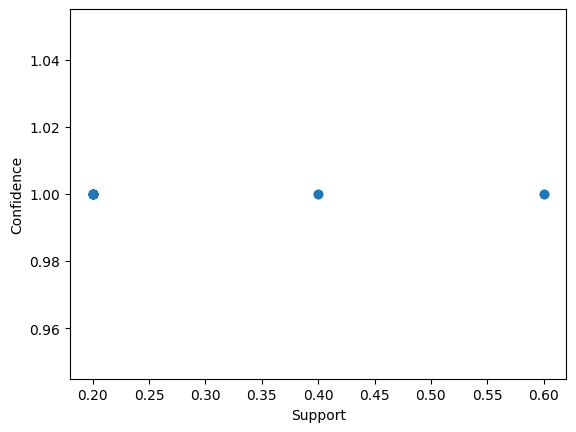

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(rules['support'], rules['confidence'])
plt.xlabel('Support')
plt.ylabel('Confidence')
plt.show()